# Import Dependencies

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

Loading the dataset 

Since the dataset is a csv file we would load it using pandas

In [2]:
import zipfile
with zipfile.ZipFile("archive (2).zip", "r") as zip_ref:
    file = zip_ref.namelist()[0]
    df = pd.read_csv(zip_ref.open(file))

** Inferences

In this section I imported dependencies to be used later when working e.g sckitlearn for machine learning. And I loaded the data using pandas

# Exploring the data

In [3]:
df.head()

,incident_id,crime_type,district,city,state,address,latitude,longitude,incident_datetime,officer_id,...,victim_gender,victim_phone,weapon_used,severity,case_status,resolution,num_arrests,property_loss_usd,reported_online,notes
0,INC001115,asslt,Sou,Maplewood,GA,2830 Cedar Lane,170.284100,-77.500710,2024-04-16 08:45:03,OFF0078,...,Unknown,6223265920,Firearm,2,Open,No Arrest,NaN,NaN,True,Incident at 2830 Cedar Lane. Officer responded...
1,INC004706,burglary,southeast,Maplewood,OH,2361 Park Rd,29.422717,-77.167016,2022-01-11 22:03:29,OFF0059,...,NaN,241-973-4826,Firearm,3,NaN,NaN,2.0,44839.49,yes,Incident at 2361 Park Rd. Officer responded at...
2,INC002249,Homocide,Southwest,Lakewood,AZ,1067 Main St,39.411460,-98.615298,2022-04-14 11:39:24,OFF0088,...,Other,244-584-7696,KNIFE,1,CLOSED,warning,2.0,15963.38,YES,Incident at 1067 Main St. Officer responded at...
3,INC000021,Property Damage,Cen,Springfield,AZ,4713 Washington Ave,28.633439,-99.030051,2020-12-09 15:14:24,OFF0077,...,NaN,5021227484,hands,Low,Resolved,NaN,5.0,48680.14,False,Incident at 4713 Washington Ave. Officer respo...
4,INC000488,Domestc Violence,North,Lakewood,PA,1371 River Rd,34.217850,-121.614731,2021-07-24 20:08:13,OFF0083,...,M,9698766873,Unarmed,MEDIUM,Closed,Warning Issued,2.0,23513.01,YES,NaN


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 5250
Number of columns: 33


In [5]:
# Column names
print("Column names:", df.columns.tolist())


Column names: ['incident_id', 'crime_type', 'district', 'city', 'state', 'address', 'latitude', 'longitude', 'incident_datetime', 'officer_id', 'officer_first_name', 'officer_last_name', 'badge_number', 'suspect_id', 'suspect_first_name', 'suspect_last_name', 'suspect_age', 'suspect_gender', 'suspect_race', 'victim_id', 'victim_first_name', 'victim_last_name', 'victim_age', 'victim_gender', 'victim_phone', 'weapon_used', 'severity', 'case_status', 'resolution', 'num_arrests', 'property_loss_usd', 'reported_online', 'notes']


In [6]:
# Checking data types
df.dtypes

incident_id            object
crime_type             object
district               object
city                   object
state                  object
address                object
latitude              float64
longitude             float64
incident_datetime      object
officer_id             object
officer_first_name     object
officer_last_name      object
badge_number          float64
suspect_id             object
suspect_first_name     object
suspect_last_name      object
suspect_age           float64
suspect_gender         object
suspect_race           object
victim_id              object
victim_first_name      object
victim_last_name       object
victim_age            float64
victim_gender          object
victim_phone           object
weapon_used            object
severity               object
case_status            object
resolution             object
num_arrests           float64
property_loss_usd      object
reported_online        object
notes                  object
dtype: obj

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5250 entries, 0 to 5249
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   incident_id         5250 non-null   object 
 1   crime_type          5250 non-null   object 
 2   district            5250 non-null   object 
 3   city                5250 non-null   object 
 4   state               5250 non-null   object 
 5   address             5250 non-null   object 
 6   latitude            4992 non-null   float64
 7   longitude           4961 non-null   float64
 8   incident_datetime   4910 non-null   object 
 9   officer_id          5250 non-null   object 
 10  officer_first_name  5250 non-null   object 
 11  officer_last_name   5250 non-null   object 
 12  badge_number        4938 non-null   float64
 13  suspect_id          4440 non-null   object 
 14  suspect_first_name  4440 non-null   object 
 15  suspect_last_name   4440 non-null   object 
 16  suspec

In [8]:
# Check for missing values
missing_values = df.isnull().sum()
print("Missing values per column: \n", missing_values)

Missing values per column: 
 incident_id              0
crime_type               0
district                 0
city                     0
state                    0
address                  0
latitude               258
longitude              289
incident_datetime      340
officer_id               0
officer_first_name       0
officer_last_name        0
badge_number           312
suspect_id             810
suspect_first_name     810
suspect_last_name      810
suspect_age           1097
suspect_gender        1413
suspect_race          1601
victim_id              257
victim_first_name      257
victim_last_name       257
victim_age             562
victim_gender         1000
victim_phone          1056
weapon_used            970
severity               355
case_status            731
resolution             951
num_arrests            333
property_loss_usd      436
reported_online        504
notes                 1069
dtype: int64


In [9]:
# Check for duplicates
duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 200


In [10]:
# Check for duplicate incident_id values
df["incident_id"].duplicated().sum()

200

** Inferences

In this section I explored the data and discovered missing values,inconsistent data types and incorrect spellings. I plan to clean it in the next section

# Data Cleaning and Preparation

In [11]:
# Check for missing values and their percentage
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

missing_summary.sort_values("Missing Percentage", ascending=False)

,Missing Values,Missing Percentage
suspect_race,1601,30.50
suspect_gender,1413,26.91
suspect_age,1097,20.90
notes,1069,20.36
victim_phone,1056,20.11
victim_gender,1000,19.05
weapon_used,970,18.48
resolution,951,18.11
suspect_last_name,810,15.43
suspect_first_name,810,15.43


In [12]:
# Check for duplicate rows
df.duplicated().sum()

200

In [13]:
# Check for duplicate incident_id values
df["incident_id"].duplicated().sum()

200

 # Cleaning Catgorical columns

In [14]:
# Identify categorical columns
categorical_columns = [
    "crime_type",
    "district",
    "city",
    "state",
    "suspect_gender",
    "suspect_race",
    "victim_gender",
    "weapon_used",
    "severity",
    "case_status",
    "resolution",
    "reported_online"
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts(dropna=False).head(20))


 crime_type
crime_type
Fire Setting      84
DV                82
ARSON             80
Deception         79
Drug Offence      79
KIDNAPPING        78
Arsen             78
trespassing       77
Hacking           76
Dom. Violence     75
Trespassing       74
Kidnaping         73
Roberry           71
Drunk Driving     71
Cybercrime        69
THEFT             68
arson             68
Sexual Assault    67
HOMICIDE          67
FRAUD             66
Name: count, dtype: int64

 district
district
Nor           273
Sou           265
SOUTHWEST     106
South         102
NORTH         101
Northeast      96
Mid            95
West           95
Southwest      94
west           94
northwest      94
North          94
Central        93
central        93
NORTHWEST      92
 Northeast     92
 Southeast     92
Cen            92
MIDTOWN        91
NORTHEAST      90
Name: count, dtype: int64

 city
city
Riverside      740
Centerville    691
Lakewood       664
Springfield    656
Oakdale        634
Maplewood      62

In [15]:
# Standardize capitalization and spaces
text_columns = [
    "crime_type",
    "district",
    "city",
    "state",
    "suspect_gender",
    "suspect_race",
    "victim_gender",
    "weapon_used",
    "severity",
    "case_status",
    "resolution"
]

for column in text_columns:
    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
        .str.lower()
    )

In [16]:
for column in text_columns:
    print("\n", column)
    print(df[column].value_counts(dropna=False).head(20))


 crime_type
crime_type
theft                215
trespassing          213
arson                205
kidnapping           198
fraud                190
homicide             179
burglary             175
sexual assault       174
robbery              172
cyber crime          164
assault              157
drug offense         156
vandalism            153
dui                  114
domestic violence    108
dv                    84
fire setting          84
drug offence          81
hacking               80
arsen                 80
Name: count, dtype: Int64

 district
district
southwest    465
west         462
northeast    449
central      446
midtown      438
north        434
northwest    430
south        426
southeast    399
east         393
nor          283
sou          270
mid           97
cen           96
wes           82
eas           80
Name: count, dtype: Int64

 city
city
riverside      740
centerville    691
lakewood       664
springfield    656
oakdale        634
maplewood      622
fairvi

In [17]:
# Checking for unusual categories
for column in text_columns:
    print(column.upper())
    print(df[column].dropna().unique())

CRIME_TYPE
<StringArray>
[              'asslt',            'burglary',            'homocide',
     'property damage',    'domestc violence', 'breaking & entering',
             'robbery',        'manslaughter',                 'b&e',
           'narcotics',             'burglry',               'theft',
 'fraudulent activity',        'drug offense',       'armed robbery',
               'arsen',           'abduction',            'graffiti',
            'trespass',         'cyber crime',         'trespassing',
      'sexual assault',               'fraud',       'theft/larceny',
             'larceny',               'arson',            'homicide',
        'tresspassing',          'cybercrime',             'hacking',
             'assault',      'sexual assualt',        'fire setting',
        'drug offence',       'drunk driving',                'duii',
              'robbry',           'vandalism',            'vandlism',
              'murder',           'kidnaping',          'kidnappi

In [18]:
# Correcting spelling errors
crime_type_corrections = {
    "asslt": "assault",
    "burgiry": "burglary",
    "roberry": "robbery",
    "robrry": "robbery",
    "vandlism": "vandalism",
    "kidnaping": "kidnapping",
    "trepassing": "trespassing",
    "trespassing": "trespassing",
    "cyber crime": "cybercrime",
    "property damage": "property damage",
    "b&e": "breaking & entering",
    "dom. violence": "domestic violence",
    "sex assault": "sexual assault",
    "sa": "sexual assault",
    "cyber crime": "cybercrime"
    }



df["crime_type"] = df["crime_type"].replace(crime_type_corrections)

In [19]:
df["crime_type"].value_counts()

crime_type
kidnapping             275
sexual assault         270
robbery                246
cybercrime             237
vandalism              217
theft                  215
trespassing            213
arson                  205
assault                202
fraud                  190
domestic violence      185
homicide               179
burglary               175
drug offense           156
dui                    114
breaking & entering     93
dv                      84
fire setting            84
drug offence            81
arsen                   80
deception               80
hacking                 80
drunk driving           74
abduction               68
graffiti                68
fraudulent activity     67
duii                    66
sexual assualt          66
murder                  64
trespass                64
assault & battery       63
tresspassing            63
d.u.i.                  62
online fraud            62
burglry                 61
narcotics               61
drugs            

In [20]:
df["district"] = (
    df["district"]
    .astype("string")
    .str.strip()
    .str.lower()
)

In [21]:
district_corrections = {
    "nor": "north",
    "sou": "south",
    "cen": "central",
    "mid": "midtown",
    "eas": "east",
    "wes": "west"
}

df["district"] = df["district"].replace(district_corrections)

In [22]:
gender_columns = ["suspect_gender", "victim_gender"]

for column in gender_columns:
    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
        .str.lower()
    )

In [23]:
gender_corrections = {
    "m": "male",
    "f": "female"
}

for column in gender_columns:
    df[column] = df[column].replace(gender_corrections)

In [24]:
for column in gender_columns:
    print("\n", column)
    print(df[column].value_counts(dropna=False))


 suspect_gender
suspect_gender
female     1645
male       1554
<NA>       1413
unknown     323
other       315
Name: count, dtype: Int64

 victim_gender
victim_gender
male       1824
female     1683
<NA>       1000
unknown     383
other       360
Name: count, dtype: Int64


In [25]:
df["suspect_race"] = (
    df["suspect_race"]
    .astype("string")
    .str.strip()
    .str.lower()
)

In [26]:
df["suspect_race"].value_counts(dropna=False)

suspect_race
<NA>        1601
black        780
hispanic     745
white        712
asian        706
unknown      367
other        339
Name: count, dtype: Int64

In [27]:
df["weapon_used"] = (
    df["weapon_used"]
    .astype("string")
    .str.strip()
    .str.lower()
)

In [28]:
weapon_corrections = {
    "knife": "knife",
    "gun": "gun",
    "pistol": "pistol",
    "firearm": "firearm",
    "hands/feet": "hands/feet",
    "hands": "hands/feet",
    "blunt object": "blunt object",
    "unarmed": "unarmed"
}

df["weapon_used"] = df["weapon_used"].replace(weapon_corrections)

In [29]:
df["weapon_used"].value_counts(dropna=False)

weapon_used
<NA>            970
hands/feet      685
knife           674
blunt object    661
firearm         622
unarmed         361
rifle           346
gun             318
pistol          310
bat             303
Name: count, dtype: Int64

In [30]:
df["severity"] = (
    df["severity"]
    .astype("string")
    .str.strip()
    .str.lower()
)

In [31]:
severity_corrections = {
    "1": "low",
    "2": "medium",
    "3": "high",
    "4": "critical",
    "med": "medium",
    "crit": "critical"
}

df["severity"] = df["severity"].replace(severity_corrections)

In [32]:
df["severity"].value_counts(dropna=False)

severity
medium      1401
critical    1384
low         1076
high        1034
<NA>         355
Name: count, dtype: Int64

In [33]:
df["case_status"] = (
    df["case_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

In [34]:
status_corrections = {
    "pendng": "pending",
    "investgation": "under investigation"
}

df["case_status"] = df["case_status"].replace(status_corrections)

In [35]:
df["case_status"].value_counts(dropna=False)

case_status
closed                 1141
open                   1132
under investigation    1120
pending                 737
<NA>                    731
resolved                389
Name: count, dtype: Int64

In [36]:
df["resolution"] = (
    df["resolution"]
    .astype("string")
    .str.strip()
    .str.lower()
)

In [37]:
resolution_corrections = {
    "arres made": "arrest made",
    "no arrest": "no arrest",
    "warning": "warning issued",
    "dismissed": "case dismissed"
}

df["resolution"] = df["resolution"].replace(resolution_corrections)

In [38]:
df["resolution"].value_counts(dropna=False)

resolution
arrest made       1471
warning issued     969
<NA>               951
case dismissed     935
no arrest          924
Name: count, dtype: Int64

In [39]:
df["reported_online"] = (
    df["reported_online"]
    .astype("string")
    .str.strip()
    .str.lower()
)

In [40]:
online_corrections = {
    "yes": "yes",
    "true": "yes",
    "1": "yes",
    "no": "no",
    "false": "no",
    "0": "no"
}

df["reported_online"] = df["reported_online"].replace(online_corrections)

In [41]:
df["reported_online"].value_counts(dropna=False)

reported_online
no      2405
yes     2341
<NA>     504
Name: count, dtype: Int64

** Inferences

In this section I cleaned categorical columns by correcting data types,spellings

# Cleaning Numerical Columns

In [42]:
df["property_loss_usd"].head(10)

0         NaN
1    44839.49
2    15963.38
3    48680.14
4    23513.01
5         NaN
6         NaN
7    19075.36
8    34452.47
9    35339.52
Name: property_loss_usd, dtype: object

In [43]:
df["property_loss_usd"] = (
    df["property_loss_usd"]
    .astype("string")
    .str.replace("$", "")
    .str.replace(",", "")
    .str.strip()
)

In [44]:
df["property_loss_usd"] = pd.to_numeric(
    df["property_loss_usd"],
    errors="coerce"
)

df["property_loss_usd"].dtype

Float64Dtype()

In [45]:
# Checking for possible property loss
df[df["property_loss_usd"] < 0][
    ["incident_id", "crime_type", "property_loss_usd"]
]

,incident_id,crime_type,property_loss_usd
12,INC003052,burglry,-34291.84
88,INC002074,assault,-43515.93
101,INC002490,arson,-12396.77
107,INC000645,burglary,-47202.73
143,INC004335,assault,-19857.76
...,...,...,...
5161,INC002367,cybercrime,-8606.74
5190,INC004869,drug offense,-26266.85
5225,INC003368,fraudulent activity,-19874.76
5232,INC001139,drug offense,-39929.32


In [46]:
df[df["suspect_age"] < 0][
    ["incident_id", "suspect_age"]
]

,incident_id,suspect_age
1,INC004706,-28.0
121,INC001614,-22.0
130,INC000951,-70.0
140,INC001252,-64.0
161,INC003482,-48.0
...,...,...
5183,INC003821,-65.0
5189,INC003770,-42.0
5235,INC004598,-53.0
5240,INC002095,-21.0


In [47]:
df[df["suspect_age"] > 100][
    ["incident_id", "suspect_age"]
]

,incident_id,suspect_age
3,INC000021,262.0
13,INC000524,162.0
101,INC002490,236.0
171,INC003171,231.0
233,INC000243,157.0
...,...,...
5194,INC000230,242.0
5200,INC002384,251.0
5219,INC001967,265.0
5228,INC004074,185.0


In [48]:
df[df["victim_age"] < 0][
    ["incident_id", "victim_age"]
]

,incident_id,victim_age
13,INC000524,-41.0
44,INC002377,-65.0
58,INC000403,-54.0
81,INC000888,-80.0
84,INC003014,-33.0
...,...,...
5194,INC000230,-33.0
5213,INC003898,-72.0
5219,INC001967,-41.0
5228,INC004074,-67.0


In [49]:
df[df["victim_age"] > 100][
    ["incident_id", "victim_age"]
]

,incident_id,victim_age
1,INC004706,231.0
3,INC000021,243.0
25,INC002571,292.0
78,INC000527,287.0
94,INC001105,157.0
...,...,...
5118,INC004111,282.0
5138,INC003926,195.0
5162,INC003502,256.0
5187,INC001365,180.0


In [50]:
df[df["num_arrests"] < 0][
    ["incident_id", "num_arrests"]
]

,incident_id,num_arrests
11,INC003264,-5.0
45,INC000950,-5.0
84,INC003014,-1.0
132,INC003007,-2.0
173,INC002264,-4.0
...,...,...
5155,INC001580,-2.0
5181,INC001792,-4.0
5185,INC000300,-2.0
5203,INC000581,-1.0


In [51]:
df[df["num_arrests"] < 100][
    ["incident_id", "num_arrests"]
]

,incident_id,num_arrests
1,INC004706,2.0
2,INC002249,2.0
3,INC000021,5.0
4,INC000488,2.0
5,INC000661,1.0
...,...,...
5245,INC003247,2.0
5246,INC000314,5.0
5247,INC002761,4.0
5248,INC001022,1.0


In [52]:
# Claening negative values in property_loss_usd
df.loc[
    df["property_loss_usd"] < 0,
    "property_loss_usd"
] = np.nan

(df["property_loss_usd"] < 0).sum()

0

In [53]:
df.loc[
    (df["suspect_age"] < 0) |
    (df["suspect_age"] > 100),
    "suspect_age"
] = np.nan

(df["suspect_age"] < 0).sum()

0

In [54]:
df.loc[
    (df["victim_age"] < 0) |
    (df["victim_age"] > 100),
    "victim_age"
] = np.nan

In [55]:
df.loc[
    df["num_arrests"] < 0,
    "num_arrests"
] = np.nan

In [56]:
numeric_columns = [
    "latitude",
    "longitude",
    "suspect_age",
    "victim_age",
    "num_arrests",
    "property_loss_usd"
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
latitude,4992.0,40.778811,23.243225,25.00242,30.966472,36.967123,43.051502,199.9842
longitude,4961.0,-88.60761,37.214207,-121.975849,-108.040512,-94.65644,-80.588056,99.7873
suspect_age,3820.0,45.354712,17.428524,15.0,30.0,46.0,60.0,75.0
victim_age,4280.0,49.864252,23.296849,10.0,30.0,50.0,70.0,90.0
num_arrests,4733.0,2.464821,1.718417,0.0,1.0,2.0,4.0,5.0
property_loss_usd,4469.0,24989.239709,14404.671529,20.66,12705.46,24801.34,37434.99,49998.3


In [57]:
# Convert incident_datetime to its correct datatype
df["incident_datetime"] = pd.to_datetime(
    df["incident_datetime"],
    errors="coerce"
)

df["incident_datetime"].dtype
df["incident_datetime"].head()

0   2024-04-16 08:45:03
1   2022-01-11 22:03:29
2   2022-04-14 11:39:24
3   2020-12-09 15:14:24
4   2021-07-24 20:08:13
Name: incident_datetime, dtype: datetime64[ns]

In [58]:
# Creating useful datetime features
df["incident_year"] = df["incident_datetime"].dt.year
df["incident_month"] = df["incident_datetime"].dt.month
df["incident_day"] = df["incident_datetime"].dt.day_name()
df["incident_hour"] = df["incident_datetime"].dt.hour

In [59]:
df[
    [
        "incident_datetime",
        "incident_year",
        "incident_month",
        "incident_day",
        "incident_hour"
    ]
].head(10)

,incident_datetime,incident_year,incident_month,incident_day,incident_hour
0,2024-04-16 08:45:03,2024.0,4.0,Tuesday,8.0
1,2022-01-11 22:03:29,2022.0,1.0,Tuesday,22.0
2,2022-04-14 11:39:24,2022.0,4.0,Thursday,11.0
3,2020-12-09 15:14:24,2020.0,12.0,Wednesday,15.0
4,2021-07-24 20:08:13,2021.0,7.0,Saturday,20.0
5,NaT,NaN,NaN,NaN,NaN
6,2021-10-03 05:17:02,2021.0,10.0,Sunday,5.0
7,2023-09-30 14:49:01,2023.0,9.0,Saturday,14.0
8,2021-01-22 02:37:24,2021.0,1.0,Friday,2.0
9,2021-03-29 04:16:18,2021.0,3.0,Monday,4.0


In [60]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
]

missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

,Missing Values,Missing Percentage
suspect_race,1601,30.50
suspect_age,1430,27.24
suspect_gender,1413,26.91
notes,1069,20.36
victim_phone,1056,20.11
victim_gender,1000,19.05
victim_age,970,18.48
weapon_used,970,18.48
resolution,951,18.11
suspect_last_name,810,15.43


** Inferences

In this section I cleaned numerical features by correcting negative values and inconsistent data types.

# Dealing with missing values

In [61]:
numerical_columns = [
    "suspect_age",
    "victim_age",
    "num_arrests",
    "property_loss_usd"
]

for column in numerical_columns:
    df[column] = df[column].fillna(
        df[column].median()
    )
df[numerical_columns].isnull().sum()

suspect_age          0
victim_age           0
num_arrests          0
property_loss_usd    0
dtype: int64

In [62]:
categorical_columns = [
    "suspect_race",
    "suspect_gender",
    "victim_gender",
    "weapon_used",
    "case_status",
    "resolution"
]

for column in categorical_columns:
    df[column] = df[column].fillna("unknown")

df[categorical_columns].isnull().sum()

suspect_race      0
suspect_gender    0
victim_gender     0
weapon_used       0
case_status       0
resolution        0
dtype: int64

In [63]:
# Standardize the gender column
gender_columns = [
    "suspect_gender",
    "victim_gender"
]

for column in gender_columns:
    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    df[column] = df[column].replace({
        "m": "male",
        "f": "female"
    })

In [64]:
print("Suspect gender:")
print(df["suspect_gender"].value_counts(dropna=False))

print("\nVictim gender:")
print(df["victim_gender"].value_counts(dropna=False))

Suspect gender:
suspect_gender
unknown    1736
female     1645
male       1554
other       315
Name: count, dtype: Int64

Victim gender:
victim_gender
male       1824
female     1683
unknown    1383
other       360
Name: count, dtype: Int64


In [65]:
df["suspect_race"] = (
    df["suspect_race"]
    .astype("string")
    .str.strip()
    .str.lower()
)
df["suspect_race"].value_counts(dropna=False)

suspect_race
unknown     1968
black        780
hispanic     745
white        712
asian        706
other        339
Name: count, dtype: Int64

In [66]:
df["weapon_used"] = (
    df["weapon_used"]
    .astype("string")
    .str.strip()
    .str.lower()
)

df["weapon_used"] = df["weapon_used"].replace({
    "hands": "hands/feet"
})

df["weapon_used"].value_counts(dropna=False)

weapon_used
unknown         970
hands/feet      685
knife           674
blunt object    661
firearm         622
unarmed         361
rifle           346
gun             318
pistol          310
bat             303
Name: count, dtype: Int64

In [67]:
df["case_status"] = (
    df["case_status"]
    .astype("string")
    .str.strip()
    .str.lower()
)

df["case_status"] = df["case_status"].replace({
    "pendng": "pending",
    "investgation": "under investigation"
})

df["case_status"].value_counts(dropna=False)

case_status
closed                 1141
open                   1132
under investigation    1120
pending                 737
unknown                 731
resolved                389
Name: count, dtype: Int64

In [68]:
df["resolution"] = (
    df["resolution"]
    .astype("string")
    .str.strip()
    .str.lower()
)

df["resolution"] = df["resolution"].replace({
    "arres made": "arrest made",
    "warning": "warning issued",
    "dismissed": "case dismissed"
})

df["resolution"].value_counts(dropna=False)

resolution
arrest made       1471
warning issued     969
unknown            951
case dismissed     935
no arrest          924
Name: count, dtype: Int64

In [69]:
df["severity"].value_counts(dropna=False)

severity
medium      1401
critical    1384
low         1076
high        1034
<NA>         355
Name: count, dtype: Int64

In [70]:
# Outliers
df[
    [
        "suspect_age",
        "victim_age",
        "num_arrests",
        "property_loss_usd"
    ]
].describe()

,suspect_age,victim_age,num_arrests,property_loss_usd
count,5250.000000,5250.000000,5250.000000,5250.0
mean,45.530476,49.889333,2.419048,24961.28739
std,14.868879,21.034462,1.637465,13290.066469
min,15.000000,10.000000,0.000000,20.66
25%,36.000000,34.000000,1.000000,14698.4425
50%,46.000000,50.000000,2.000000,24801.34
75%,55.000000,65.000000,4.000000,35224.65
max,75.000000,90.000000,5.000000,49998.3


In [71]:
Q1 = df["property_loss_usd"].quantile(0.25)
Q3 = df["property_loss_usd"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Lower limit: -16090.868750000007
Upper limit: 66013.96125000001


In [72]:
property_outliers = df[
    (df["property_loss_usd"] < lower_limit) |
    (df["property_loss_usd"] > upper_limit)
]

print("Number of property-loss outliers:", len(property_outliers))

Number of property-loss outliers: 0


In [73]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nDuplicate rows:",
      df.duplicated().sum())

print("\nDuplicate incident IDs:",
      df["incident_id"].duplicated().sum())

print("\nData types:")
print(df.dtypes)

Rows: 5250
Columns: 37

Duplicate rows: 200

Duplicate incident IDs: 200

Data types:
incident_id                   object
crime_type            string[python]
district              string[python]
city                  string[python]
state                 string[python]
address                       object
latitude                     float64
longitude                    float64
incident_datetime     datetime64[ns]
officer_id                    object
officer_first_name            object
officer_last_name             object
badge_number                 float64
suspect_id                    object
suspect_first_name            object
suspect_last_name             object
suspect_age                  float64
suspect_gender        string[python]
suspect_race          string[python]
victim_id                     object
victim_first_name             object
victim_last_name              object
victim_age                   float64
victim_gender         string[python]
victim_phone              

** Inferences

In this section I dealt with numeric missing values by filling it with the median because median is robust to outliers and I replaced missing categorical values with 'unknown' rather than guessing a category. This preserves the fact that the information was unavailable.I investigated outliers rather than automatically deleting them. I used the IQR method to identify unusually large or small values, then considered whether they were plausible observations. Legitimate extreme values were retained.

# Exploratory Data Analysis

In [74]:
crime_counts = df["crime_type"].value_counts()

crime_counts

crime_type
kidnapping             275
sexual assault         270
robbery                246
cybercrime             237
vandalism              217
theft                  215
trespassing            213
arson                  205
assault                202
fraud                  190
domestic violence      185
homicide               179
burglary               175
drug offense           156
dui                    114
breaking & entering     93
dv                      84
fire setting            84
drug offence            81
arsen                   80
deception               80
hacking                 80
drunk driving           74
abduction               68
graffiti                68
fraudulent activity     67
duii                    66
sexual assualt          66
murder                  64
trespass                64
assault & battery       63
tresspassing            63
d.u.i.                  62
online fraud            62
burglry                 61
narcotics               61
drugs            

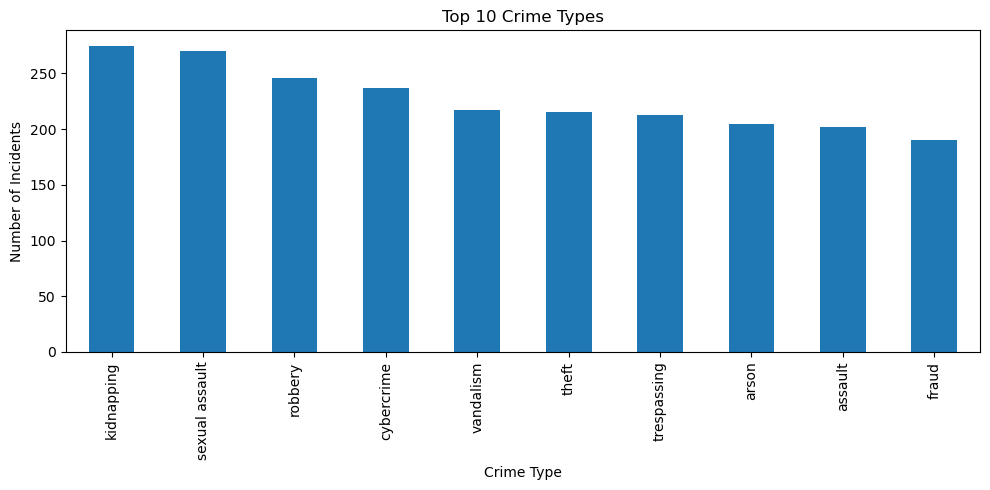

In [75]:
crime_counts.head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Crime Types")
plt.xlabel("Crime Type")
plt.ylabel("Number of Incidents")
plt.tight_layout()
plt.show()

In [76]:
district_counts = df["district"].value_counts()

district_counts

district
north        717
south        696
west         544
central      542
midtown      535
east         473
southwest    465
northeast    449
northwest    430
southeast    399
Name: count, dtype: Int64

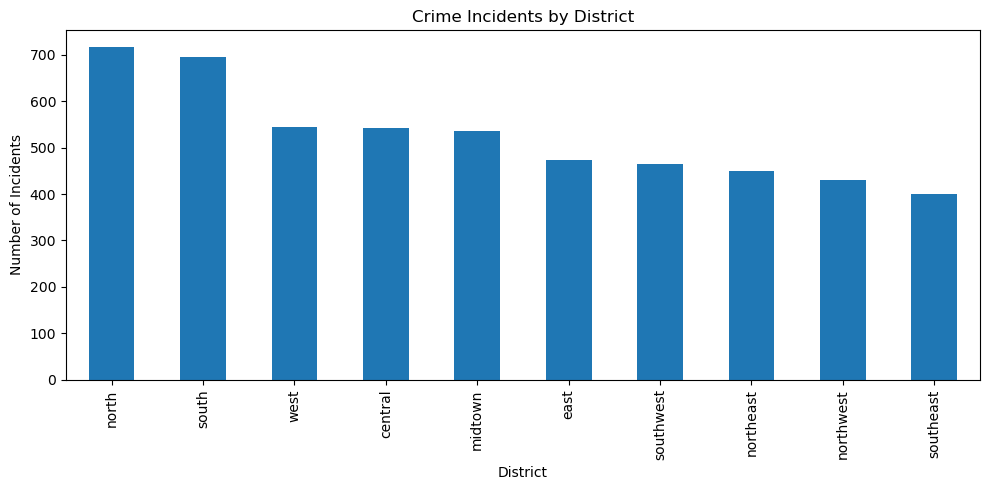

In [77]:
district_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Crime Incidents by District")
plt.xlabel("District")
plt.ylabel("Number of Incidents")
plt.tight_layout()
plt.show()

In [78]:
severity_counts = df["severity"].value_counts()

severity_counts

severity
medium      1401
critical    1384
low         1076
high        1034
Name: count, dtype: Int64

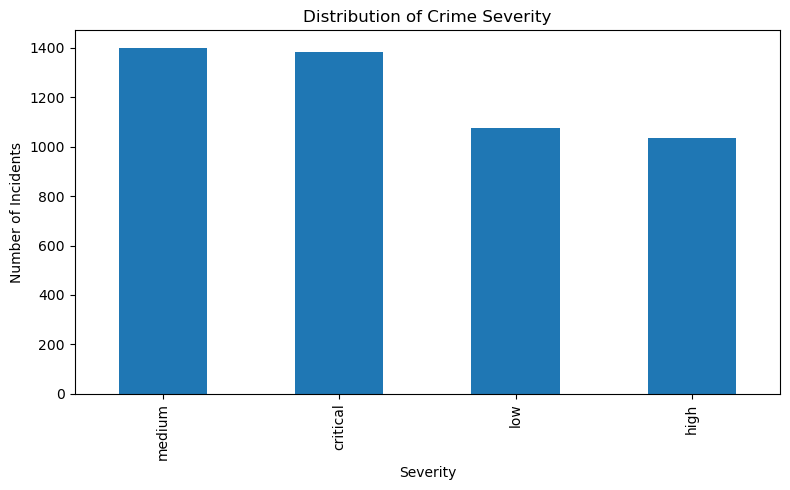

In [79]:
severity_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Crime Severity")
plt.xlabel("Severity")
plt.ylabel("Number of Incidents")
plt.tight_layout()
plt.show()

In [80]:
hour_counts = df["incident_hour"].value_counts().sort_index()

hour_counts

incident_hour
0.0     192
1.0     182
2.0     238
3.0     174
4.0     203
5.0     195
6.0     198
7.0     222
8.0     205
9.0     234
10.0    185
11.0    161
12.0    177
13.0    184
14.0    184
15.0    181
16.0    171
17.0    194
18.0    175
19.0    179
20.0    175
21.0    188
22.0    170
23.0    163
Name: count, dtype: int64

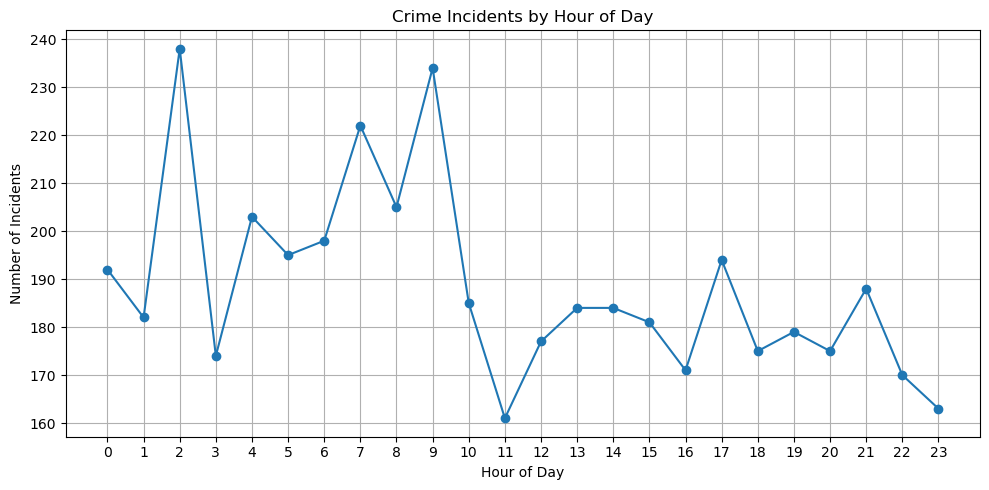

In [81]:
hour_counts.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Crime Incidents by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Incidents")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

In [82]:
crime_severity = pd.crosstab(
    df["crime_type"],
    df["severity"]
)

crime_severity

severity,critical,high,low,medium
crime_type,,,,
abduction,14,16,15,21
armed robbery,0,0,0,1
armed robbery,10,11,3,13
arsen,24,21,13,17
arson,64,29,42,49
assault,46,36,45,64
assault & battery,20,17,8,15
battery,14,12,14,11
breaking & entering,24,20,22,25


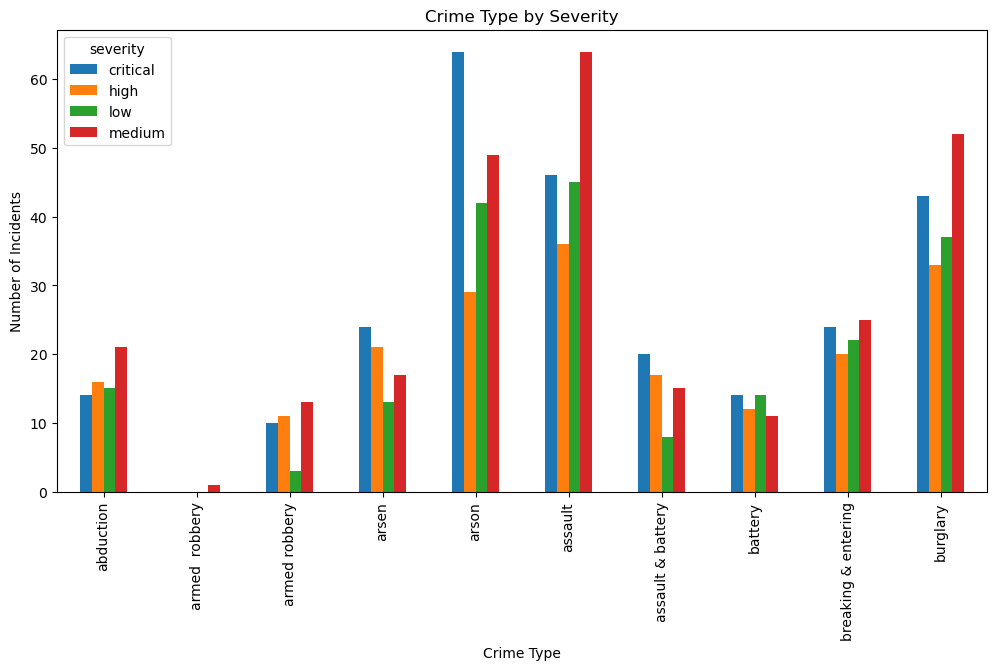

In [83]:
crime_severity.head(10).plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Crime Type by Severity")
plt.xlabel("Crime Type")
plt.ylabel("Number of Incidents")
plt.show()

In [84]:
df.groupby("severity")["property_loss_usd"].mean().round(2)

severity
critical    25111.38
high        25226.94
low         24919.86
medium      24661.15
Name: property_loss_usd, dtype: Float64

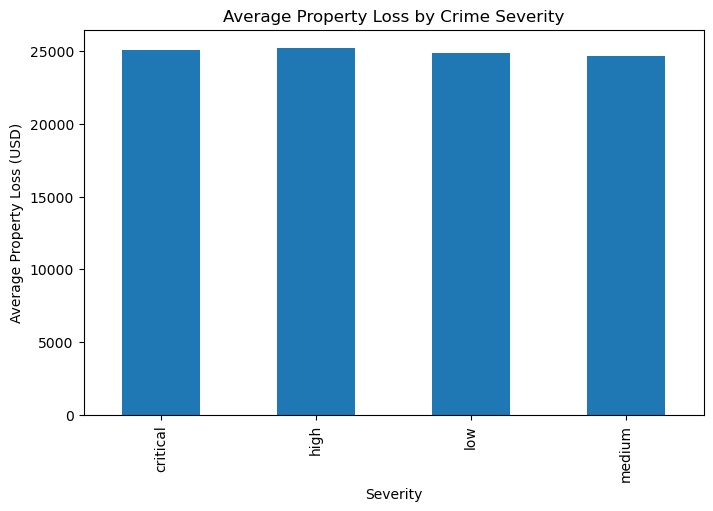

In [85]:
df.groupby("severity")["property_loss_usd"].mean().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Property Loss by Crime Severity")
plt.xlabel("Severity")
plt.ylabel("Average Property Loss (USD)")
plt.show()

In [86]:
weapon_counts = df["weapon_used"].value_counts()

weapon_counts

weapon_used
unknown         970
hands/feet      685
knife           674
blunt object    661
firearm         622
unarmed         361
rifle           346
gun             318
pistol          310
bat             303
Name: count, dtype: Int64

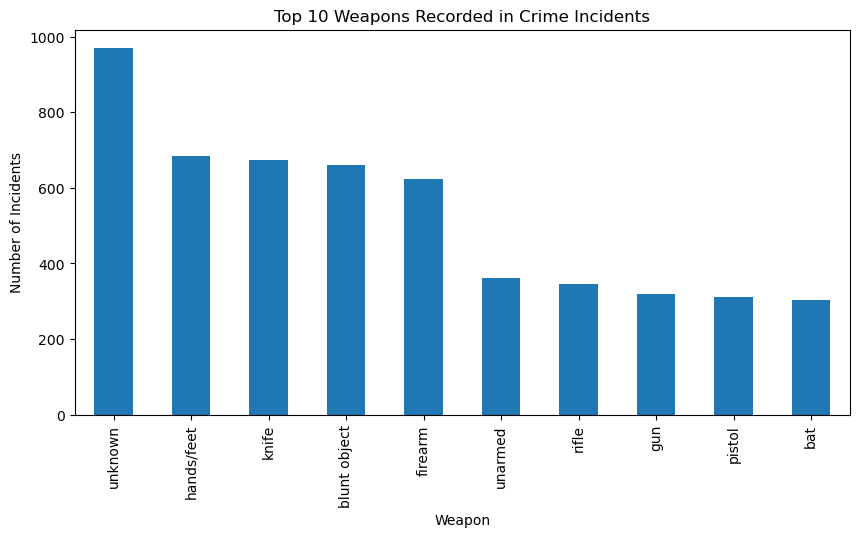

In [87]:
weapon_counts.head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Weapons Recorded in Crime Incidents")
plt.xlabel("Weapon")
plt.ylabel("Number of Incidents")
plt.show()

In [88]:
pd.crosstab(
    df["weapon_used"],
    df["severity"]
)

severity,critical,high,low,medium
weapon_used,,,,
bat,88,56,57,81
blunt object,190,130,126,172
firearm,155,133,131,155
gun,95,61,69,78
hands/feet,179,135,130,196
knife,180,142,153,151
pistol,78,61,57,91
rifle,86,65,68,105
unarmed,86,54,80,114


In [89]:
numerical_eda = df[
    [
        "suspect_age",
        "victim_age",
        "num_arrests",
        "property_loss_usd",
        "incident_year",
        "incident_month",
        "incident_hour"
    ]
]

correlation_matrix = numerical_eda.corr()

correlation_matrix.round(2)

,suspect_age,victim_age,num_arrests,property_loss_usd,incident_year,incident_month,incident_hour
suspect_age,1.00,0.00,0.02,0.02,-0.01,-0.01,0.00
victim_age,0.00,1.00,0.01,-0.01,-0.01,-0.00,-0.01
num_arrests,0.02,0.01,1.00,-0.01,0.01,0.03,-0.01
property_loss_usd,0.02,-0.01,-0.01,1.00,-0.01,0.03,0.01
incident_year,-0.01,-0.01,0.01,-0.01,1.00,-0.02,-0.02
incident_month,-0.01,-0.00,0.03,0.03,-0.02,1.00,0.02
incident_hour,0.00,-0.01,-0.01,0.01,-0.02,0.02,1.00


<Axes: >

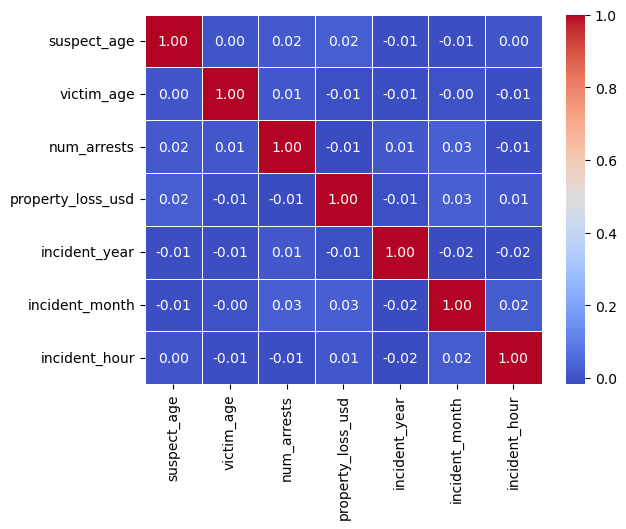

In [90]:
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

All off-diagonal feature pairs exhibit near-zero correlation coefficients 

 There is zero linear correlation between suspect_age and victim_age, indicating that the ages of individuals involved in an incident do not track together linearly.
 
property_loss_usd shows no linear relationship  withsuspect_age or num_rests

 Time-based dimensions (incident_year, incident_month, incident_hour) do not linearly influence the scale of property loss or the likelihood of higher arrests.

Absence of Multicollinearity


In [91]:
df.groupby("severity")["num_arrests"].mean().round(2)

severity
critical    2.42
high        2.37
low         2.45
medium      2.43
Name: num_arrests, dtype: float64

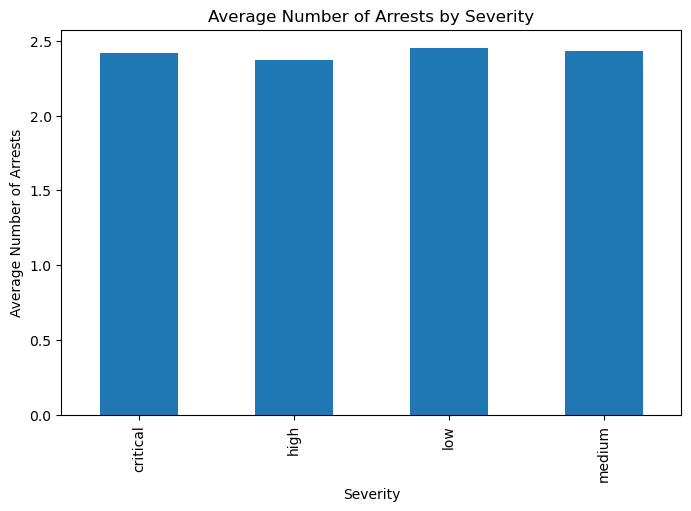

In [92]:
df.groupby("severity")["num_arrests"].mean().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Number of Arrests by Severity")
plt.xlabel("Severity")
plt.ylabel("Average Number of Arrests")
plt.show()

In [93]:
yearly_crimes = df["incident_year"].value_counts().sort_index()

yearly_crimes

incident_year
2018.0    622
2019.0    653
2020.0    632
2021.0    652
2022.0    669
2023.0    628
2024.0    674
Name: count, dtype: int64

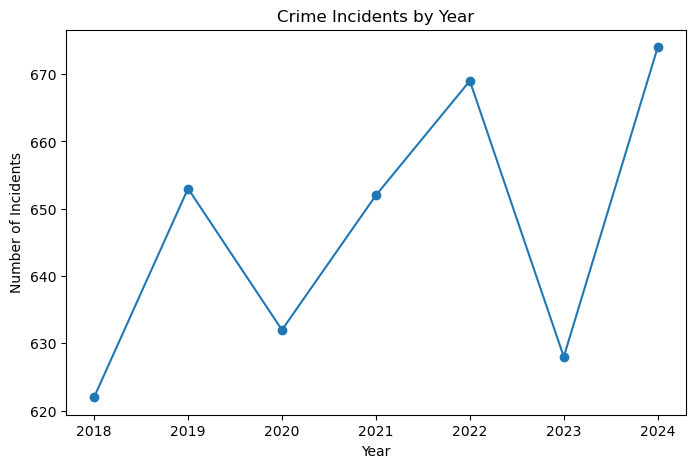

In [94]:
plt.figure(figsize=(8, 5))

plt.plot(
    yearly_crimes.index,
    yearly_crimes.values,
    marker="o"
)

plt.title("Crime Incidents by Year")
plt.xlabel("Year")
plt.ylabel("Number of Incidents")
plt.xticks(yearly_crimes.index)

plt.show()

In [95]:
district_severity = pd.crosstab(
    df["district"],
    df["severity"]
)

district_severity

severity,critical,high,low,medium
district,,,,
central,139,114,108,136
east,126,77,96,137
midtown,141,89,134,130
north,198,142,145,184
northeast,132,76,89,113
northwest,105,99,82,126
south,178,140,146,193
southeast,94,84,79,106
southwest,123,99,84,130


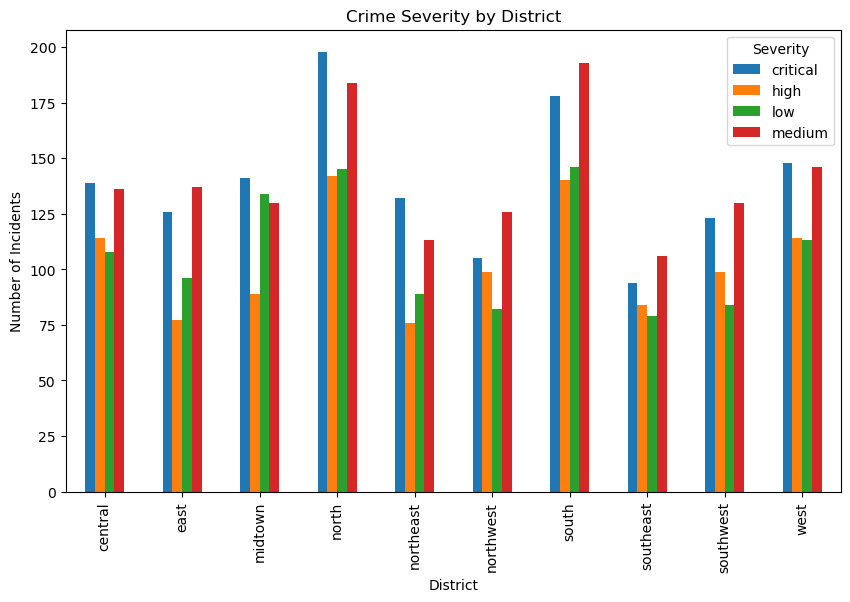

In [96]:
district_severity.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Crime Severity by District")
plt.xlabel("District")
plt.ylabel("Number of Incidents")
plt.legend(title="Severity")
plt.show()

In [97]:
age_summary = df[
    ["suspect_age", "victim_age"]
].describe()

age_summary

,suspect_age,victim_age
count,5250.000000,5250.000000
mean,45.530476,49.889333
std,14.868879,21.034462
min,15.000000,10.000000
25%,36.000000,34.000000
50%,46.000000,50.000000
75%,55.000000,65.000000
max,75.000000,90.000000


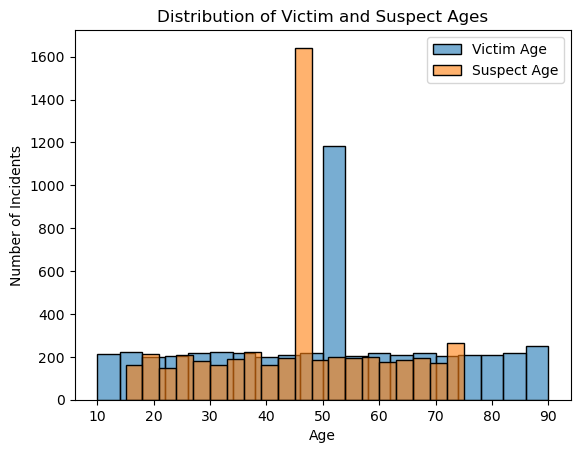

In [98]:
sns.histplot(
    df["victim_age"],
    bins=20,
    alpha=0.6,
    label="Victim Age"
)

sns.histplot(
    df["suspect_age"],
    bins=20,
    alpha=0.6,
    label="Suspect Age"
)

plt.title("Distribution of Victim and Suspect Ages")
plt.xlabel("Age")
plt.ylabel("Number of Incidents")
plt.legend()
plt.show()

In [99]:
crime_severity_pct = pd.crosstab(
    df["crime_type"],
    df["severity"],
    normalize="index"
) * 100

crime_severity_pct.round(1)

severity,critical,high,low,medium
crime_type,,,,
abduction,21.2,24.2,22.7,31.8
armed robbery,0.0,0.0,0.0,100.0
armed robbery,27.0,29.7,8.1,35.1
arsen,32.0,28.0,17.3,22.7
arson,34.8,15.8,22.8,26.6
assault,24.1,18.8,23.6,33.5
assault & battery,33.3,28.3,13.3,25.0
battery,27.5,23.5,27.5,21.6
breaking & entering,26.4,22.0,24.2,27.5


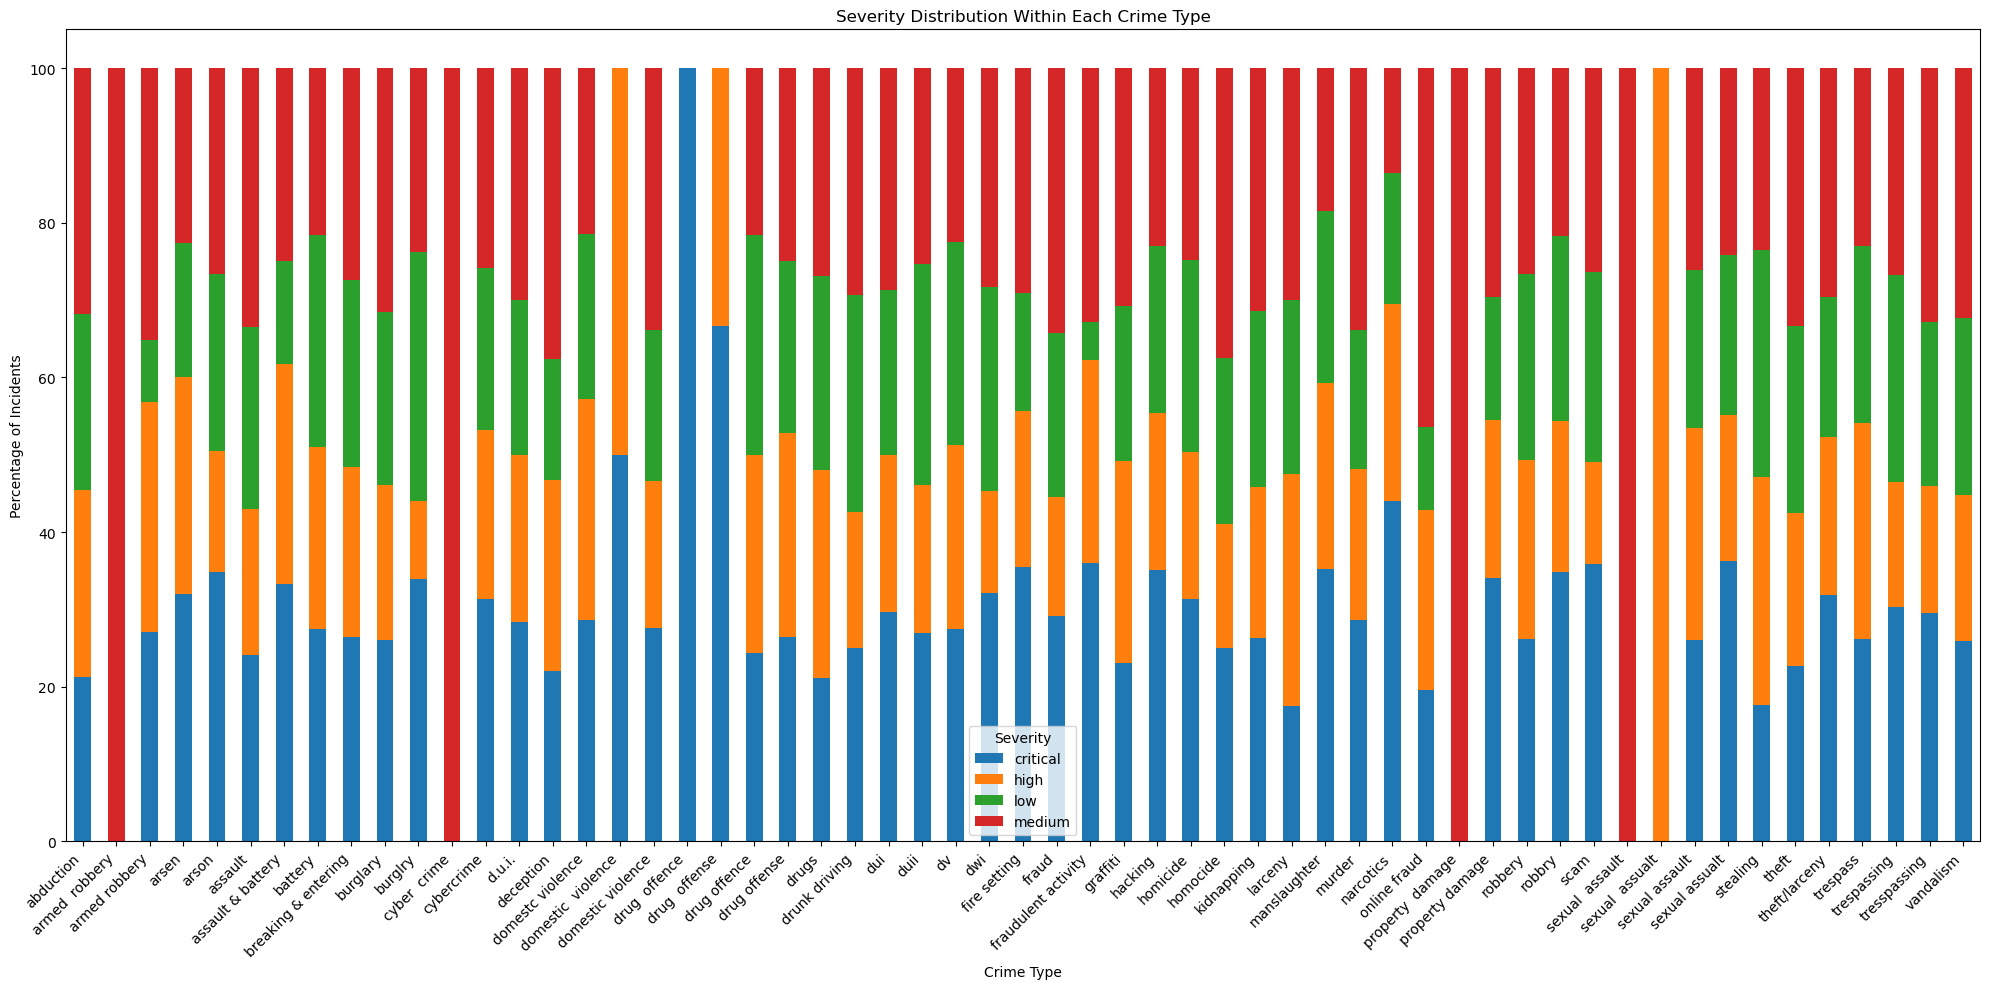

In [100]:
crime_severity_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(20, 10)
)

plt.title("Severity Distribution Within Each Crime Type")
plt.xlabel("Crime Type")
plt.ylabel("Percentage of Incidents")
plt.xticks(rotation=45, ha="right")

plt.legend(title="Severity")
plt.tight_layout()
plt.show()

In [101]:
monthly_crimes = (
    df["incident_month"]
    .value_counts()
    .sort_index()
)

monthly_crimes

incident_month
1.0     365
2.0     360
3.0     404
4.0     352
5.0     394
6.0     352
7.0     401
8.0     400
9.0     351
10.0    412
11.0    364
12.0    375
Name: count, dtype: int64

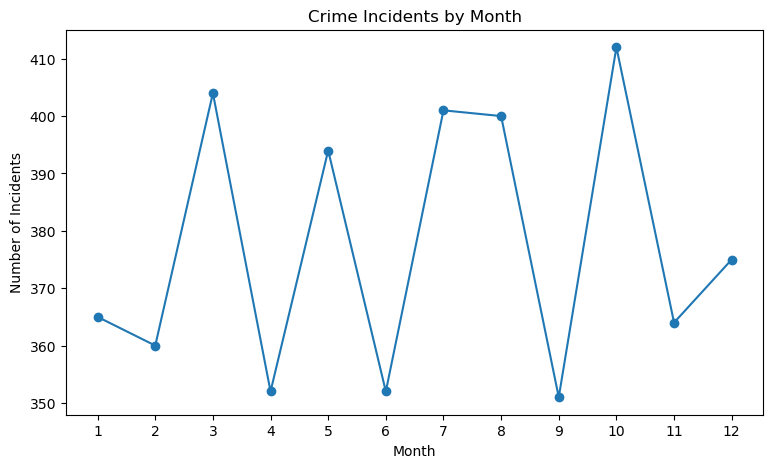

In [102]:
plt.figure(figsize=(9, 5))

plt.plot(
    monthly_crimes.index,
    monthly_crimes.values,
    marker="o"
)

plt.title("Crime Incidents by Month")
plt.xlabel("Month")
plt.ylabel("Number of Incidents")
plt.xticks(range(1, 13))

plt.show()

In [103]:
print("Top Crime Types:")
print(df["crime_type"].value_counts().head(10))

print("\nSeverity Distribution:")
print(df["severity"].value_counts())

print("\nDistrict Distribution:")
print(df["district"].value_counts())

print("\nIncidents by Year:")
print(df["incident_year"].value_counts().sort_index())

Top Crime Types:
crime_type
kidnapping        275
sexual assault    270
robbery           246
cybercrime        237
vandalism         217
theft             215
trespassing       213
arson             205
assault           202
fraud             190
Name: count, dtype: Int64

Severity Distribution:
severity
medium      1401
critical    1384
low         1076
high        1034
Name: count, dtype: Int64

District Distribution:
district
north        717
south        696
west         544
central      542
midtown      535
east         473
southwest    465
northeast    449
northwest    430
southeast    399
Name: count, dtype: Int64

Incidents by Year:
incident_year
2018.0    622
2019.0    653
2020.0    632
2021.0    652
2022.0    669
2023.0    628
2024.0    674
Name: count, dtype: int64


In [104]:
severity_loss = (
    df.groupby("severity")["property_loss_usd"]
    .mean()
    .round(2)
)

severity_loss

severity
critical    25111.38
high        25226.94
low         24919.86
medium      24661.15
Name: property_loss_usd, dtype: Float64

In [105]:
severity_arrests = (
    df.groupby("severity")["num_arrests"]
    .mean()
    .round(2)
)

severity_arrests

severity
critical    2.42
high        2.37
low         2.45
medium      2.43
Name: num_arrests, dtype: float64

In [106]:
severity_arrests = (
    df.groupby("severity")["num_arrests"]
    .mean()
    .round(2)
)

severity_arrests

severity
critical    2.42
high        2.37
low         2.45
medium      2.43
Name: num_arrests, dtype: float64

## Key EDA Observations and Inferences

### 1. Crime Types
Observation: The dataset contains several crime types, with some occurring more frequently than others.

Inference: Crime incidents are not evenly distributed across crime categories, meaning some crime types are more common in the dataset. Kidnapping is the most common crime type.

### 2. Severity
Observation: The severity categories are distributed across Low, Medium, High, and Critical incidents.

Inference: Severity provides a meaningful target for classification because the dataset contains multiple severity classes. The most common class of severity is medium.

### 3. District
Observation: Crime incidents are distributed differently across districts.

Inference: The district variable may contain useful information for understanding geographical patterns in crime incidents. The highest district where crime occur is the north.

### 4. Time
Observation: Crime incidents vary by year, month, and time of day.

Inference: Crime activity shows temporal patterns that may be useful for further analysis and prediction.

### 5. Property Loss
Observation: Average property loss differs across severity categories.

Inference: Property loss may have a relationship with incident severity, although this relationship does not imply causation.

### 6. Crime Type and Severity
Observation: The proportion of severity levels varies across crime types.

Inference: Some crime types are more strongly associated with higher severity categories in this dataset.

# Feature Enginerering

In [107]:
# Create suspect age groups
age_bins = [0, 17, 29, 44, 59, float("inf")]
age_labels = [
    "Minor",
    "Young Adult",
    "Adult",
    "Middle Aged",
    "Senior"
]

df["suspect_age_group"] = pd.cut(
    df["suspect_age"],
    bins=age_bins,
    labels=age_labels
)

In [108]:
# Create victim age groups
df["victim_age_group"] = pd.cut(
    df["victim_age"],
    bins=age_bins,
    labels=age_labels
)

In [109]:
print("Suspect Age Groups:")
print(df["suspect_age_group"].value_counts())

print("\nVictim Age Groups:")
print(df["victim_age_group"].value_counts())

Suspect Age Groups:
suspect_age_group
Middle Aged    2420
Senior          993
Adult           930
Young Adult     747
Minor           160
Name: count, dtype: int64

Victim Age Groups:
victim_age_group
Middle Aged    1771
Senior         1626
Adult           798
Young Adult     619
Minor           436
Name: count, dtype: int64


In [110]:
# Create property loss categories
loss_bins = [-1, 999, 4999, 9999, float("inf")]

loss_labels = [
    "Low Loss",
    "Moderate Loss",
    "High Loss",
    "Very High Loss"
]

df["property_loss_band"] = pd.cut(
    df["property_loss_usd"],
    bins=loss_bins,
    labels=loss_labels
)

df["property_loss_band"].value_counts()

property_loss_band
Very High Loss    4371
High Loss          454
Moderate Loss      335
Low Loss            90
Name: count, dtype: int64

In [111]:
# Create binary features
df["weapon_involved"] = (
    df["weapon_used"].isin(["unknown", "unarmed"])
).astype(int)

df["weapon_involved"].value_counts()

weapon_involved
0    3919
1    1331
Name: count, dtype: int64

In [112]:
df["property_loss_recorded"] = (
    df["property_loss_usd"] > 0
).astype(int)
df["property_loss_recorded"].value_counts()

property_loss_recorded
1    5250
Name: count, dtype: int64

In [113]:
X = df.drop(columns=["severity"])
y = df["severity"]

In [119]:
columns_to_drop = [
    "incident_id",
    "officer_id",
    "officer_first_name",
    "officer_last_name",
    "badge_number",
    "suspect_id",
    "suspect_first_name",
    "suspect_last_name",
    "victim_id",
    "victim_first_name",
    "victim_last_name",
    "victim_phone",
    "address",
    "notes",
    "case_status",
    "num_arrests",
    "resolution"
    
]
X = X.drop(columns=columns_to_drop)


In [120]:
print("Number of features:", X.shape[1])

print("\nFeatures:")
print(X.columns.tolist())

Number of features: 24

Features:
['crime_type', 'district', 'city', 'state', 'latitude', 'longitude', 'incident_datetime', 'suspect_age', 'suspect_gender', 'suspect_race', 'victim_age', 'victim_gender', 'weapon_used', 'property_loss_usd', 'reported_online', 'incident_year', 'incident_month', 'incident_day', 'incident_hour', 'suspect_age_group', 'victim_age_group', 'property_loss_band', 'weapon_involved', 'property_loss_recorded']


In [123]:
print("\nTarget distribution:")
print(y.value_counts())


Target distribution:
severity
medium      1401
critical    1384
low         1076
high        1034
Name: count, dtype: Int64


In [124]:
# Check numerical and categorical data
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['latitude', 'longitude', 'suspect_age', 'victim_age', 'property_loss_usd', 'incident_year', 'incident_month', 'incident_hour']

Categorical features:
['crime_type', 'district', 'city', 'state', 'suspect_gender', 'suspect_race', 'victim_gender', 'weapon_used', 'reported_online', 'incident_day', 'suspect_age_group', 'victim_age_group', 'property_loss_band']


In [125]:
valid_target = y.notna()

X_model = X.loc[valid_target].copy()
y_model = y.loc[valid_target].copy()

In [126]:
print("X_model shape:", X_model.shape)
print("y_model shape:", y_model.shape)
print("Missing values in y_model:", y_model.isna().sum())

X_model shape: (4895, 23)
y_model shape: (4895,)
Missing values in y_model: 0


# Building the Pipeline

In [127]:
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.20,
    random_state=42,
    stratify=y_model
)

In [128]:
for column in categorical_features:
    X_train[column] = X_train[column].astype("object")
    X_test[column] = X_test[column].astype("object")
print(X_train.dtypes)

crime_type                 object
district                   object
city                       object
state                      object
latitude                  float64
longitude                 float64
suspect_age               float64
suspect_gender             object
suspect_race               object
victim_age                float64
victim_gender              object
weapon_used                object
property_loss_usd         Float64
reported_online            object
incident_year             float64
incident_month            float64
incident_day               object
incident_hour             float64
suspect_age_group          object
victim_age_group           object
property_loss_band         object
weapon_involved             int32
property_loss_recorded      int32
dtype: object


In [129]:
time_categorical = [
        "incident_day"
    ]
for column in time_categorical:
    

    for column in time_categorical:
        if column in X_train.columns:
            X_train[column] = X_train[column].astype("object")
        if column in X_test.columns:
            X_test[column] = X_test[column].astype("object")
    X_test[column] = X_test[column].astype("object")

In [130]:
# Make sure all categorical columns can safely handle missing values

for column in categorical_features:
    X_train[column] = X_train[column].astype("object")
    X_test[column] = X_test[column].astype("object")

    X_train[column] = X_train[column].where(
        X_train[column].notna(), "unknown"
    )

    X_test[column] = X_test[column].where(
        X_test[column].notna(), "unknown"
    )

print("Categorical columns cleaned successfully.")

Categorical columns cleaned successfully.


In [151]:
from sklearn.impute import SimpleImputer
def build_pipeline(model):
    numerical_pipeline = Pipeline(
        steps = [
            ("imputer", SimpleImputer(strategy = "median")),
            ("scaler", StandardScaler())
        ]
    )
    categorical_pipeline = Pipeline(
        steps = [
            ("imputer", SimpleImputer(strategy = "most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown = "ignore"))
        ]
    )
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numerical_pipeline, numerical_features),
            ("cat", categorical_pipeline, categorical_features),
            ("classifier", model)
        ]
    )
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )
    return pipeline 

In [152]:
X_train_processed = preprocessor.fit_transform(X_train)
# Normalize repeated spaces in all categorical columns before encoding
for col in categorical_features:
    X_train[col] = (
        X_train[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )
    X_test[col] = (
        X_test[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

# Apply the known crime-type typo/spacing corrections
X_train["crime_type"] = X_train["crime_type"].replace(crime_type_corrections)
X_test["crime_type"] = X_test["crime_type"].replace(crime_type_corrections)

# Make the encoder ignore unseen categories instead of raising
categorical_pipeline.set_params(encoder__handle_unknown="ignore")

# Transform the test split
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (3916, 134)
Processed testing shape: (979, 134)


# Building Logistic Regression model

In [154]:
from sklearn.metrics import log_loss


def train_evaluate_classifier(model, X_train, y_train, X_test, y_test, model_name="None"):

    # Collecting metrics
    metrics = {}
    model.fit(X_train, y_train) # Train the Model by fitting

    # Predicting on train and test set
    y_pred_train, y_pred_test = model.predict(X_train), model.predict(X_test)
    y_proba_pred = model.predict_proba(X_test)

    # Calculating accuracy score for both train and test set
    train_score = accuracy_score(y_train, y_pred_train)
    test_score  = accuracy_score(y_test, y_pred_test)

    # calculating f1_score, precision_score, and recall_score
    f1_scores = f1_score(y_test, y_pred_test, average="weighted")
    prec_score = precision_score(y_test, y_pred_test, average="weighted")
    rec_score = recall_score(y_test, y_pred_test, average="weighted")
    loss = log_loss(y_test, y_proba_pred)
    print(F"{'====' * 10} Classification Report For {model_name} {'====' * 10}\n {classification_report(y_test, y_pred_test)}")
    metrics["Train Score"] = train_score
    metrics["Test Score"]  = test_score
    metrics["F1 Score"]   = f1_scores
    metrics["Precision Score"] = prec_score
    metrics["Recall Score"]     = rec_score
    metrics["Log Loss"]  = loss

    return (
        model, X_train, X_test, y_pred_test, y_proba_pred, metrics
    )

In [164]:
log_regress_pipeline = build_pipeline(LogisticRegression(max_iter=1000, random_state=42))

log_model, X_train, X_test, y_pred_test, y_proba_pred, logistic_metrics = (
     train_evaluate_classifier(
          log_regress_pipeline,
          X_train,
          y_train,
          X_test,
          y_test,
          model_name="Logistic Classifier"
     )
)

======================================== Classification Report For Logistic Classifier ========================================
               precision    recall  f1-score   support

    critical       0.27      0.35      0.31       277
        high       0.24      0.16      0.19       207
         low       0.18      0.11      0.13       215
      medium       0.26      0.33      0.29       280

    accuracy                           0.25       979
   macro avg       0.24      0.24      0.23       979
weighted avg       0.24      0.25      0.24       979



In [165]:
random_forest_pipeline = build_pipeline(RandomForestClassifier(n_estimators=100, random_state=42))

random_forest_model, X_train, X_test, y_pred_test, y_proba_pred, random_forest_metrics = (
     train_evaluate_classifier(
          random_forest_pipeline,
          X_train,
          y_train,
          X_test,
          y_test,
          model_name="Random Forest Classifier"
     )
)

======================================== Classification Report For Random Forest Classifier ========================================
               precision    recall  f1-score   support

    critical       0.32      0.48      0.38       277
        high       0.29      0.14      0.19       207
         low       0.34      0.15      0.21       215
      medium       0.31      0.41      0.36       280

    accuracy                           0.32       979
   macro avg       0.32      0.30      0.29       979
weighted avg       0.32      0.32      0.30       979



In [166]:
decision_tree_pipeline = build_pipeline(DecisionTreeClassifier(random_state=42))

decision_tree_model, X_train, X_test, y_pred_test, y_proba_pred, decision_tree_metrics = (
     train_evaluate_classifier(
          decision_tree_pipeline,
          X_train,
          y_train,
          X_test,
          y_test,
          model_name="Decision Tree Classifier"
     )
)

======================================== Classification Report For Decision Tree Classifier ========================================
               precision    recall  f1-score   support

    critical       0.35      0.37      0.36       277
        high       0.28      0.29      0.29       207
         low       0.29      0.27      0.28       215
      medium       0.35      0.34      0.34       280

    accuracy                           0.32       979
   macro avg       0.32      0.32      0.32       979
weighted avg       0.32      0.32      0.32       979



In [170]:
decision_tree_metrics

{'Train Score': 1.0,
 'Test Score': 0.3237997957099081,
 'F1 Score': 0.32346855373633593,
 'Precision Score': 0.3235801736678987,
 'Recall Score': 0.3237997957099081,
 'Log Loss': 24.372725785082277}

In [176]:
random_forest_metrics

{'Train Score': 1.0,
 'Test Score': 0.3166496424923391,
 'F1 Score': 0.2969160082902001,
 'Precision Score': 0.3160976529120737,
 'Recall Score': 0.3166496424923391,
 'Log Loss': 1.3364670972297077}

In [177]:
logistic_metrics

{'Train Score': 0.3465270684371808,
 'Test Score': 0.25025536261491316,
 'F1 Score': 0.2393174815384616,
 'Precision Score': 0.24045236489578112,
 'Recall Score': 0.25025536261491316,
 'Log Loss': 1.4165767496691168}

In [ ]:
 Logistic Regression pipeline
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Parameters to test
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs", "liblinear"]
}

# Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

# Train and test different parameter combinations
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1 Score:")
print(round(grid_search.best_score_, 3))

In [137]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Logistic Regression pipeline
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Parameters to test
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs", "liblinear"]
}

# Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

# Train and test different parameter combinations
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1 Score:")
print(round(grid_search.best_score_, 3))

Best parameters:
{'classifier__C': 1, 'classifier__solver': 'lbfgs'}

Best cross-validation F1 Score:
0.235


In [139]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Get the best Logistic Regression model
best_logistic_model = grid_search.best_estimator_

# Make predictions
y_pred_tuned = best_logistic_model.predict(X_test)

# Calculate evaluation metrics
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)

precision_tuned = precision_score(
    y_test,
    y_pred_tuned,
    average="weighted",
    zero_division=0
)

recall_tuned = recall_score(
    y_test,
    y_pred_tuned,
    average="weighted",
    zero_division=0
)

f1_tuned = f1_score(
    y_test,
    y_pred_tuned,
    average="weighted",
    zero_division=0
)

print("Tuned Logistic Regression Results")
print("----------------------------------")
print("Accuracy :", round(accuracy_tuned, 3))
print("Precision:", round(precision_tuned, 3))
print("Recall   :", round(recall_tuned, 3))
print("F1 Score :", round(f1_tuned, 3))

Tuned Logistic Regression Results
----------------------------------
Accuracy : 0.25
Precision: 0.24
Recall   : 0.25
F1 Score : 0.239


In [140]:
logistic_results = {
    "Model": "Tuned Logistic Regression",
    "Accuracy": accuracy_tuned,
    "Precision": precision_tuned,
    "Recall": recall_tuned,
    "F1 Score": f1_tuned
}

print(logistic_results)

{'Model': 'Tuned Logistic Regression', 'Accuracy': 0.25025536261491316, 'Precision': 0.24045236489578112, 'Recall': 0.25025536261491316, 'F1 Score': 0.2393174815384616}


In [138]:
y_pred_logistic = logistic_model.predict(X_test)

print("Predictions completed successfully.")
print("Number of predictions:", len(y_pred_logistic))

Predictions completed successfully.
Number of predictions: 979


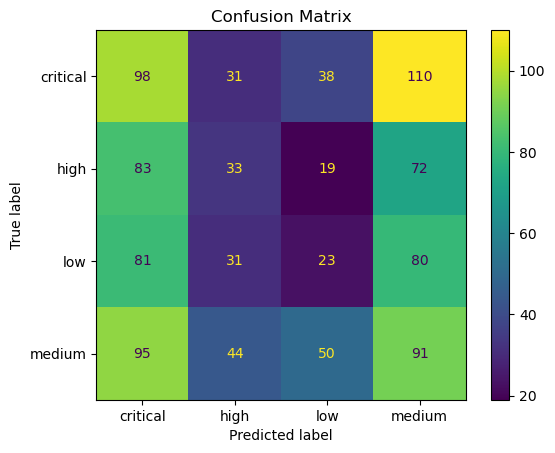

In [154]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred_logistic)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=logistic_model.classes_
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

## Random Forest Classifier

In [141]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])


In [142]:
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['latitude', 'longitude',
                                                   'suspect_age', 'victim_age',
                                                   'property_loss_usd',
                                                   'incident_year',
                                                   'incident_month',
                                                   'incident_hour']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['crime_type', 'district',
                                                   'city', 'state',
                                                   'suspect_gender',
                                                   'suspect_race',
                                                   'victim_gender',
                                                   'weapon_used',
                                                   'reported_online',
                                                   'incident_day',
                                                   'suspect_age_group',
                                                   'victim_age_group',
                                                   'property_loss_band'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [145]:
train_acc = random_forest_model.score(X_train, y_train)
print(train_acc*100)

100.0


In [146]:
print(F"""
    Train accuracy is {train_acc * 100} 
""")


    Train accuracy is 100.0 



In [150]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Make predictions on the test data
y_pred_rf = random_forest_model.predict(X_test)

# Calculate evaluation metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)

precision_rf = precision_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

recall_rf = recall_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

f1_rf = f1_score(
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", round(accuracy_rf, 3))
print("Precision:", round(precision_rf, 3))
print("Recall   :", round(recall_rf, 3))
print("F1 Score :", round(f1_rf, 3))

Random Forest Results
---------------------
Accuracy : 0.317
Precision: 0.316
Recall   : 0.317
F1 Score : 0.297


In [153]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Random Forest pipeline
random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42
    ))
])

# Parameters to test
param_grid_rf = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

# Grid Search with 5-fold cross-validation
grid_search_rf = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=param_grid_rf,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

# Train and test different parameter combinations
grid_search_rf.fit(X_train, y_train)

print("Best parameters:")
print(grid_search_rf.best_params_)

print("\nBest cross-validation F1 Score:")
print(round(grid_search_rf.best_score_, 3))

Best parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

Best cross-validation F1 Score:
0.3


In [154]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Get the best Random Forest model
best_rf_model = grid_search_rf.best_estimator_

# Make predictions
y_pred_rf_tuned = best_rf_model.predict(X_test)

# Calculate evaluation metrics
accuracy_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)

precision_rf_tuned = precision_score(
    y_test,
    y_pred_rf_tuned,
    average="weighted",
    zero_division=0
)

recall_rf_tuned = recall_score(
    y_test,
    y_pred_rf_tuned,
    average="weighted",
    zero_division=0
)

f1_rf_tuned = f1_score(
    y_test,
    y_pred_rf_tuned,
    average="weighted",
    zero_division=0
)

print("Tuned Random Forest Results")
print("---------------------------")
print("Accuracy :", round(accuracy_rf_tuned, 3))
print("Precision:", round(precision_rf_tuned, 3))
print("Recall   :", round(recall_rf_tuned, 3))
print("F1 Score :", round(f1_rf_tuned, 3))

Tuned Random Forest Results
---------------------------
Accuracy : 0.337
Precision: 0.35
Recall   : 0.337
F1 Score : 0.316


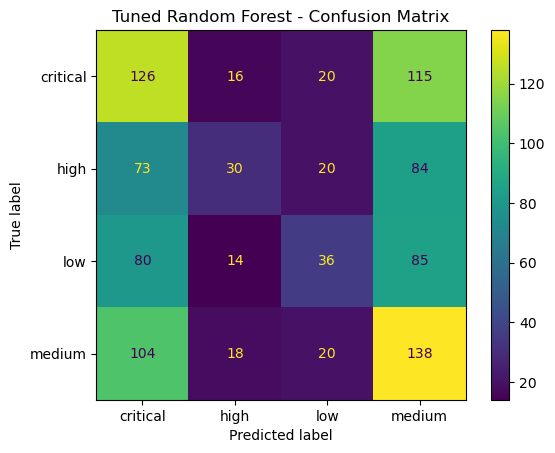

In [156]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf_tuned
)

# Display confusion matrix
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=best_rf_model.classes_
)

disp_rf.plot()

plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()

In [157]:
model_comparison = pd.DataFrame([
    {
        "Model": "Tuned Logistic Regression",
        "Accuracy": accuracy_tuned,
        "Precision": precision_tuned,
        "Recall": recall_tuned,
        "F1 Score": f1_tuned
    },
    {
        "Model": "Tuned Random Forest",
        "Accuracy": accuracy_rf_tuned,
        "Precision": precision_rf_tuned,
        "Recall": recall_rf_tuned,
        "F1 Score": f1_rf_tuned
    }
])

model_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Tuned Logistic Regression,0.250,0.24,0.250,0.239
1,Tuned Random Forest,0.337,0.35,0.337,0.316


In [158]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create the Decision Tree pipeline
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [160]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Make predictions
y_pred_dt = decision_tree_model.predict(X_test)

# Calculate metrics
accuracy_dt = accuracy_score(y_test, y_pred_dt)

precision_dt = precision_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

recall_dt = recall_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

f1_dt = f1_score(
    y_test,
    y_pred_dt,
    average="weighted",
    zero_division=0
)

print("Decision Tree Results")
print("---------------------")
print("Accuracy :", round(accuracy_dt, 3))
print("Precision:", round(precision_dt, 3))
print("Recall   :", round(recall_dt, 3))
print("F1 Score :", round(f1_dt, 3))

Decision Tree Results
---------------------
Accuracy : 0.324
Precision: 0.324
Recall   : 0.324
F1 Score : 0.323


In [161]:
from sklearn.model_selection import GridSearchCV

# Decision Tree pipeline
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

# Parameters to test
param_grid_dt = {
    "classifier__max_depth": [None, 5, 10, 15, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 5]
}

# Grid Search with 5-fold cross-validation
grid_search_dt = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid_dt,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1
)

# Train different parameter combinations
grid_search_dt.fit(X_train, y_train)

print("Best Decision Tree parameters:")
print(grid_search_dt.best_params_)

print("\nBest cross-validation F1 Score:")
print(round(grid_search_dt.best_score_, 3))

Best Decision Tree parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}

Best cross-validation F1 Score:
0.304


In [162]:
# Get the best Decision Tree model
best_dt_model = grid_search_dt.best_estimator_

# Make predictions
y_pred_dt_tuned = best_dt_model.predict(X_test)

# Calculate evaluation metrics
accuracy_dt_tuned = accuracy_score(y_test, y_pred_dt_tuned)

precision_dt_tuned = precision_score(
    y_test,
    y_pred_dt_tuned,
    average="weighted",
    zero_division=0
)

recall_dt_tuned = recall_score(
    y_test,
    y_pred_dt_tuned,
    average="weighted",
    zero_division=0
)

f1_dt_tuned = f1_score(
    y_test,
    y_pred_dt_tuned,
    average="weighted",
    zero_division=0
)

print("Tuned Decision Tree Results")
print("---------------------------")
print("Accuracy :", round(accuracy_dt_tuned, 3))
print("Precision:", round(precision_dt_tuned, 3))
print("Recall   :", round(recall_dt_tuned, 3))
print("F1 Score :", round(f1_dt_tuned, 3))

Tuned Decision Tree Results
---------------------------
Accuracy : 0.324
Precision: 0.324
Recall   : 0.324
F1 Score : 0.323


### Model Results

The modeling results indicate that predicting crime severity is challenging with the available features. Among the tuned models explicitly compared in the notebook, the **Tuned Random Forest** produced the strongest reported results, with an accuracy of approximately **33.7%** and a weighted F1-score of approximately **31.6%**.